<a href="https://colab.research.google.com/github/nachopedretti/diploup2026-TP2/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 — Análisis exploratorio (EDA)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:

df_etiq = pd.read_csv("https://raw.githubusercontent.com/nachopedretti/diploup2026-TP2/main/data/raw/smoking_prediction.csv")


In [7]:
df_etiq.head()

,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0.0,F,40.0,155.0,60.0,3.377083,0.043056,0.041667,0.041667,0.041667,...,0.506250,0.041667,0.004861,0.750000,0.791667,1.125000,Y,0.0,Y,0.0
1,1.0,F,40.0,160.0,60.0,3.375000,0.005556,0.004167,0.041667,0.041667,...,0.504861,0.041667,0.004167,0.916667,0.791667,0.750000,Y,0.0,Y,0.0
2,2.0,M,55.0,170.0,60.0,3.333333,0.005556,0.005556,0.041667,0.041667,...,0.630556,0.041667,0.041667,0.875000,0.666667,0.916667,Y,0.0,N,1.0
3,3.0,M,40.0,165.0,70.0,3.666667,0.045139,0.045139,0.041667,0.041667,...,0.588194,0.041667,0.041667,0.791667,1.083333,0.750000,Y,0.0,Y,0.0
4,4.0,F,40.0,155.0,60.0,3.583333,0.041667,0.041667,0.041667,0.041667,...,0.503472,0.041667,0.004167,0.666667,0.583333,0.916667,Y,0.0,N,0.0


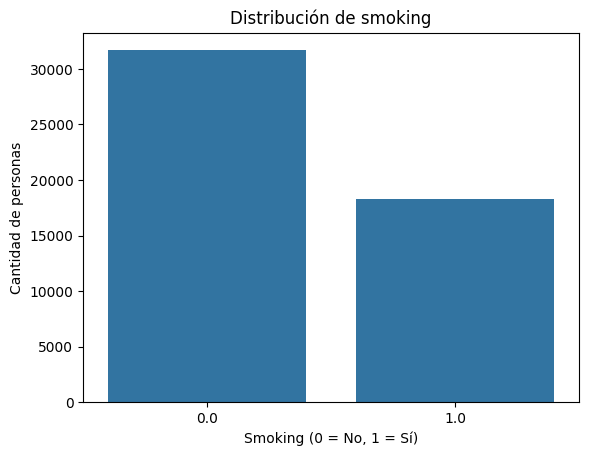

In [8]:
sns.countplot(data=df_etiq, x="smoking")
plt.title("Distribución de smoking")
plt.xlabel("Smoking (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de personas")
plt.show()

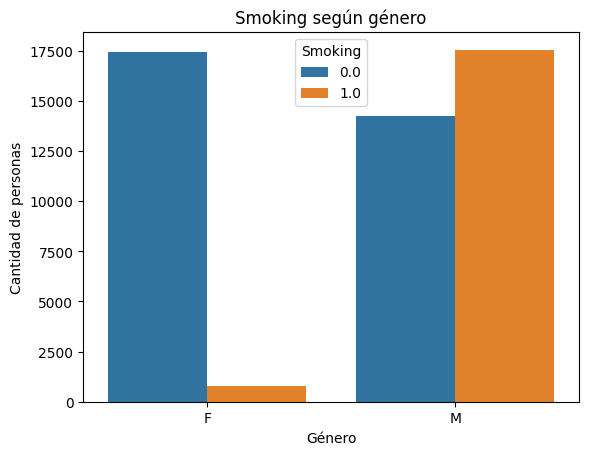

In [9]:
sns.countplot(data=df_etiq, x="gender", hue="smoking")
plt.title("Smoking según género")
plt.xlabel("Género")
plt.ylabel("Cantidad de personas")
plt.legend(title="Smoking")
plt.show()

In [10]:
pd.crosstab(df_etiq["gender"], df_etiq["smoking"],normalize="index") * 100

smoking,0.0,1.0
gender,,
F,95.723540,4.276460
M,44.783539,55.216461


**El 55% de los hombres fuma, Vs las mujeres solo fuman el 4%.**

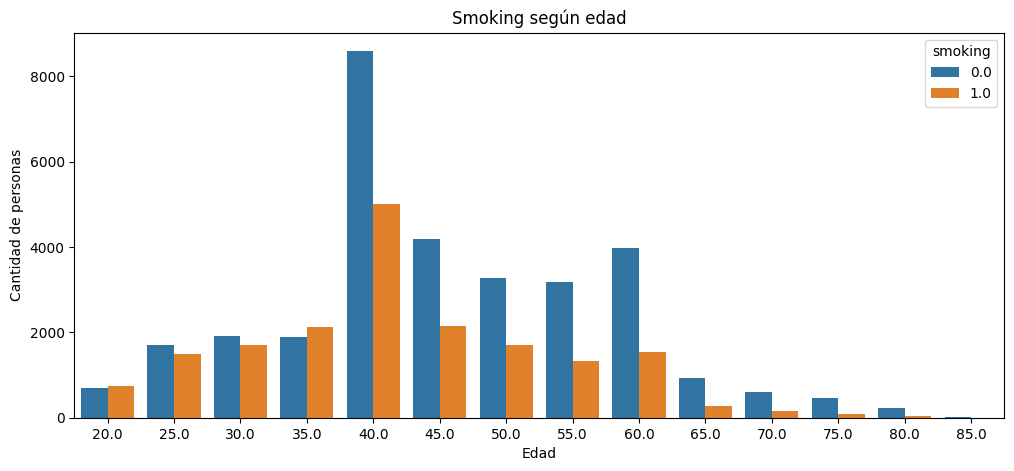

In [11]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df_etiq, x="age", hue="smoking")
plt.title("Smoking según edad")
plt.xlabel("Edad")
plt.ylabel("Cantidad de personas")
plt.show()

In [12]:
pd.crosstab(df_etiq["age"],df_etiq["smoking"],normalize="index") * 100

smoking,0.0,1.0
age,,
20.0,48.531469,51.468531
25.0,53.510140,46.489860
30.0,52.635937,47.364063
35.0,46.993042,53.006958
40.0,63.172596,36.827404
45.0,66.197851,33.802149
50.0,65.767760,34.232240
55.0,70.674357,29.325643
60.0,72.120774,27.879226


**A medida que aumenta la edad, baja el % de fumadores**

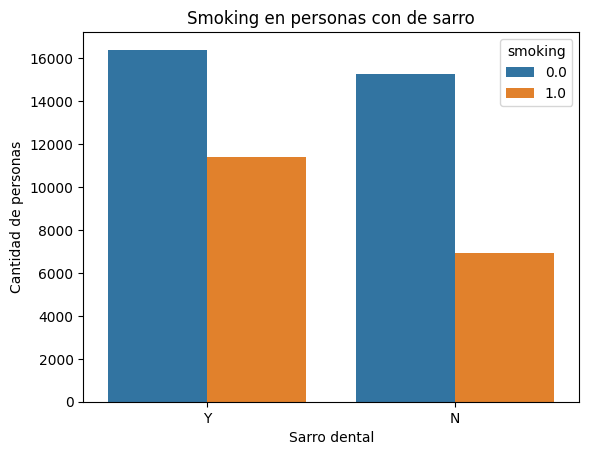

In [13]:
sns.countplot(data=df_etiq, x="tartar", hue="smoking")
plt.title("Smoking en personas con de sarro")
plt.xlabel("Sarro dental")
plt.ylabel("Cantidad de personas")
plt.show()

In [14]:
pd.crosstab(df_etiq["tartar"],df_etiq["smoking"],normalize="index") * 100

smoking,0.0,1.0
tartar,,
N,68.740714,31.259286
Y,59.026953,40.973047


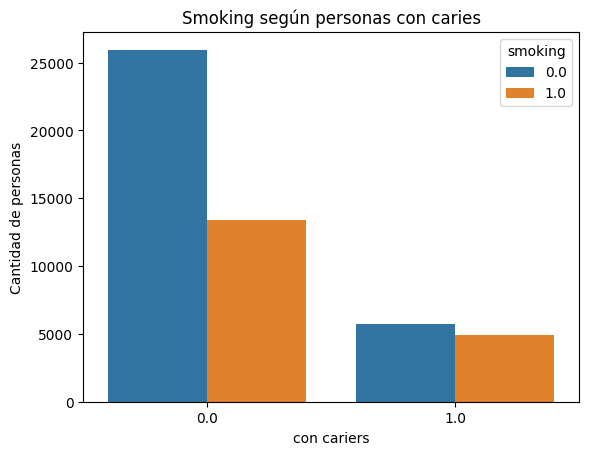

In [15]:
sns.countplot(data=df_etiq, x="dental caries", hue="smoking")
plt.title("Smoking según personas con caries")
plt.xlabel("con cariers")
plt.ylabel("Cantidad de personas")
plt.show()

In [16]:
pd.crosstab(df_etiq["dental caries"],df_etiq["smoking"],normalize="index") * 100

smoking,0.0,1.0
dental caries,,
0.0,65.943981,34.056019
1.0,53.734985,46.265015


**Las personas con sarro o caries presentan un mayor porcentaje de fumadores**

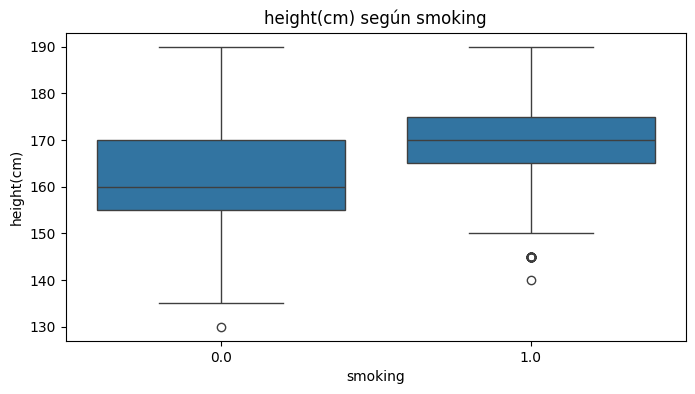

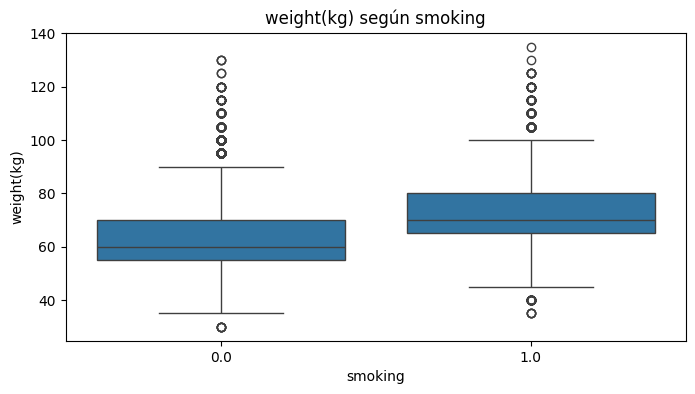

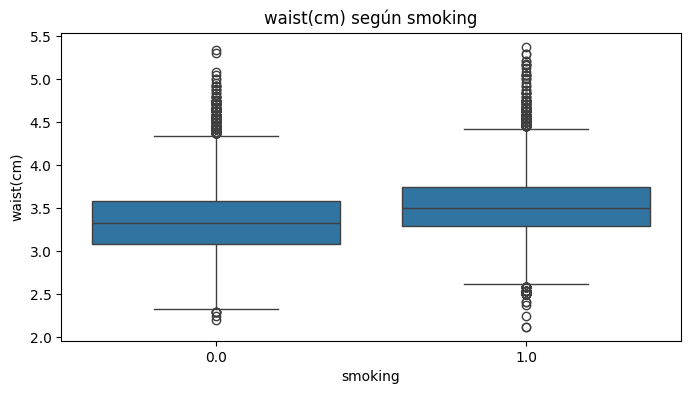

In [17]:
VarFisicas = ["height(cm)", "weight(kg)", "waist(cm)"]
for columna in VarFisicas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_etiq, x="smoking", y=columna)
    plt.title(f"{columna} según smoking")
    plt.show()

In [18]:
df_etiq.groupby("smoking")[VarFisicas].median()

,height(cm),weight(kg),waist(cm)
smoking,,,
0.0,160.0,60.0,3.333333
1.0,170.0,70.0,3.503472


**Los fumadores presentan mayores valores de altura, peso y cintura, aunque hay que ver si esta mas relacionado al genero que al fumador no fumador**

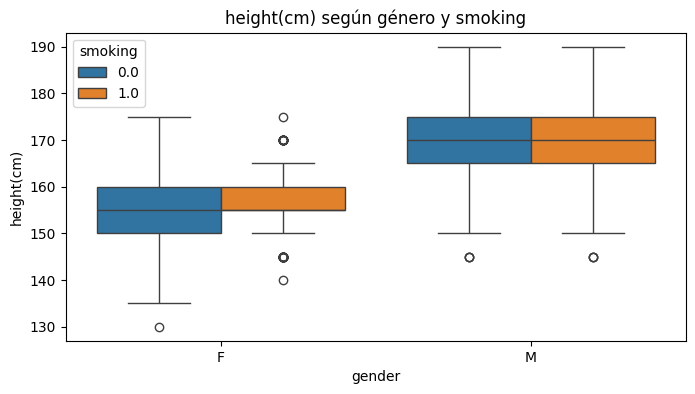

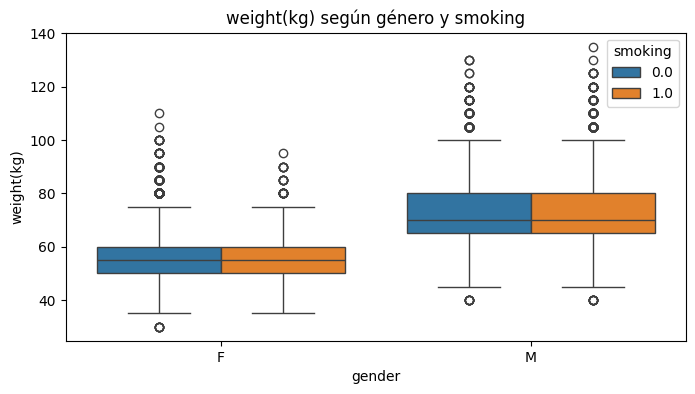

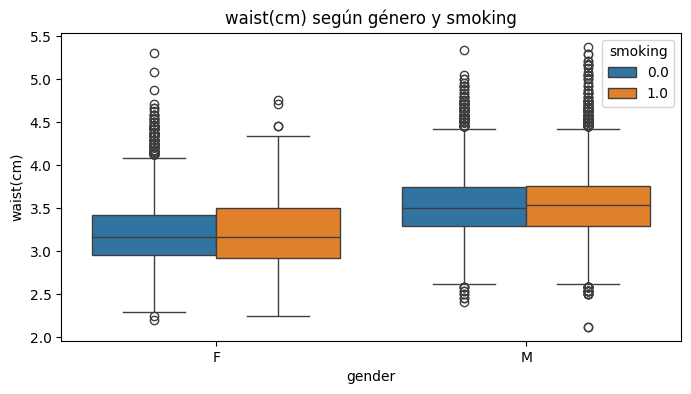

In [19]:
VarFisicas = ["height(cm)", "weight(kg)", "waist(cm)"]
for columna in VarFisicas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_etiq, x="gender", y=columna, hue="smoking")
    plt.title(f"{columna} según género y smoking")
    plt.show()

In [20]:
df_etiq.groupby(["gender", "smoking"])[VarFisicas].median()

height(cm)  weight(kg)  waist(cm)
gender smoking                                   
F      0.0           155.0        55.0   3.166667
       1.0           155.0        55.0   3.166667
M      0.0           170.0        70.0   3.503472
       1.0           170.0        70.0   3.541667

**Al separar por género, las diferencias de altura y peso desaparecen**

In [21]:
VarClinicas = ["systolic", "relaxation", "fasting blood sugar",
"Cholesterol", "triglyceride", "HDL", "LDL","hemoglobin", "serum creatinine", "AST", "ALT", "Gtp"]
df_etiq.groupby("smoking")[VarClinicas].median().T

smoking,0.0,1.0
systolic,5.000000,5.083333
relaxation,3.125000,3.250000
fasting blood sugar,3.958333,4.041667
Cholesterol,8.166667,8.083333
triglyceride,4.000000,5.500000
HDL,2.416667,2.166667
LDL,4.750000,4.625000
hemoglobin,0.584722,0.628472
serum creatinine,0.005556,0.006250
AST,0.916667,1.000000


In [22]:
medianas = df_etiq.groupby("smoking")[VarClinicas].median().T
medianas["Diferencia %"] = ((medianas[1.0] - medianas[0.0]) / medianas[0.0]) * 100
medianas.round(2)

smoking,0.0,1.0,Diferencia %
systolic,5.00,5.08,1.67
relaxation,3.12,3.25,4.00
fasting blood sugar,3.96,4.04,2.11
Cholesterol,8.17,8.08,-1.02
triglyceride,4.00,5.50,37.50
HDL,2.42,2.17,-10.34
LDL,4.75,4.62,-2.63
hemoglobin,0.58,0.63,7.48
serum creatinine,0.01,0.01,12.50
AST,0.92,1.00,9.09


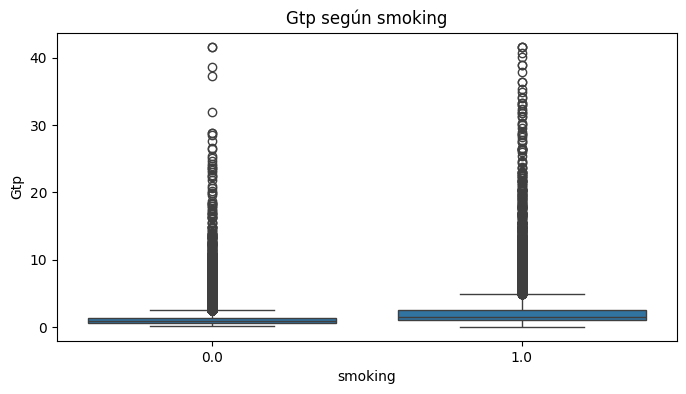

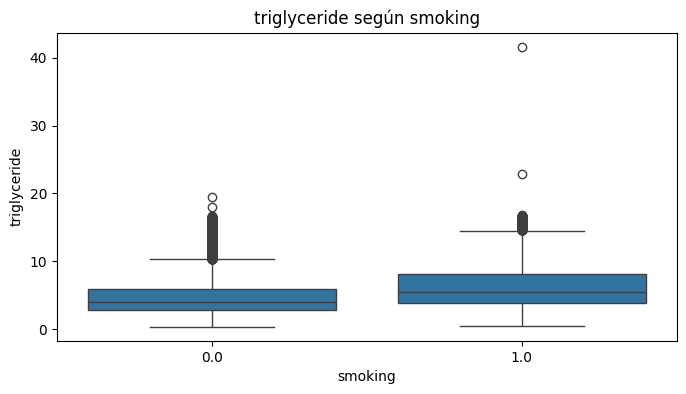

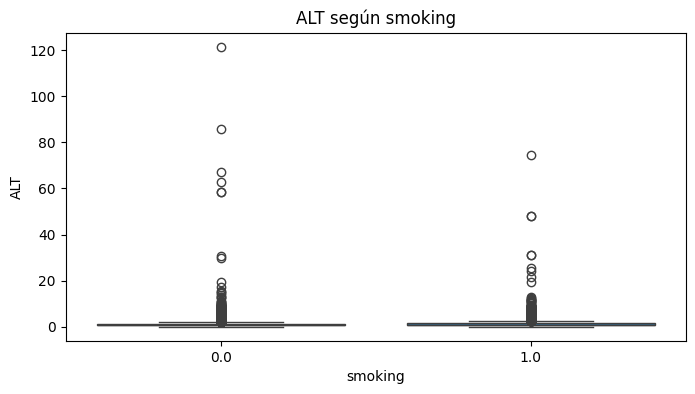

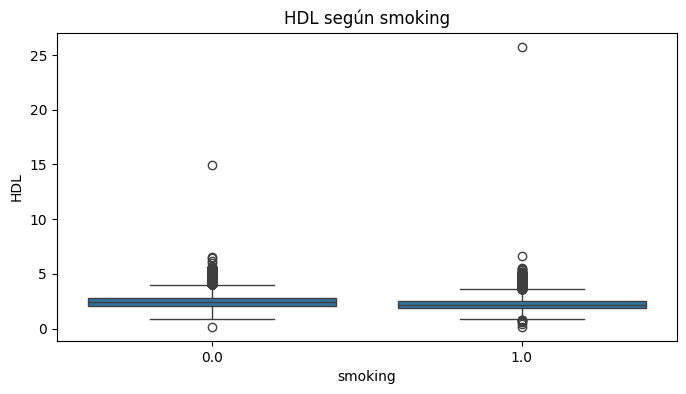

In [23]:
VarClinicasDestacadas = ["Gtp", "triglyceride", "ALT", "HDL"]
for columna in VarClinicasDestacadas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_etiq, x="smoking", y=columna)
    plt.title(f"{columna} según smoking")
    plt.show()

In [24]:
df_etiq.groupby(["gender", "smoking"])[VarClinicasDestacadas].median()

Gtp  triglyceride       ALT       HDL
gender smoking                                            
F      0.0      0.708333      3.666667  0.666667  2.583333
       1.0      0.958333      4.250000  0.666667  2.583333
M      0.0      1.166667      4.500000  1.000000  2.208333
       1.0      1.541667      5.541667  1.041667  2.125000

**Gtp y triglyceride son las variables que más se destacan, incluso después de considerar el género**

In [25]:
df_etiq[VarClinicasDestacadas].describe().T[
    ["min", "25%", "50%", "75%", "max"]
]

,min,25%,50%,75%,max
Gtp,0.041667,0.708333,1.041667,1.833333,41.625000
triglyceride,0.333333,3.083333,4.500000,6.666667,41.625000
ALT,0.041667,0.625000,0.875000,1.291667,121.416667
HDL,0.166667,1.958333,2.291667,2.750000,25.750000


**Valores maximos muy alejados de la mediana**

In [26]:
for variable in VarClinicasDestacadas:
    Q1 = df_etiq[variable].quantile(0.25)
    Q3 = df_etiq[variable].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    extremos = df_etiq[(df_etiq[variable] < limite_inferior) |
        (df_etiq[variable] > limite_superior)]
    print(variable, ":", len(extremos),
          "valores extremos (",round(len(extremos) / len(df_etiq) * 100, 2), "%)")

Gtp : 4330 valores extremos ( 8.66 %)
triglyceride : 2013 valores extremos ( 4.03 %)
ALT : 3348 valores extremos ( 6.7 %)
HDL : 903 valores extremos ( 1.81 %)


**valores extremos en las cuatro variables, principalmente en Gtp (8,66%) y ALT (6,70%)**

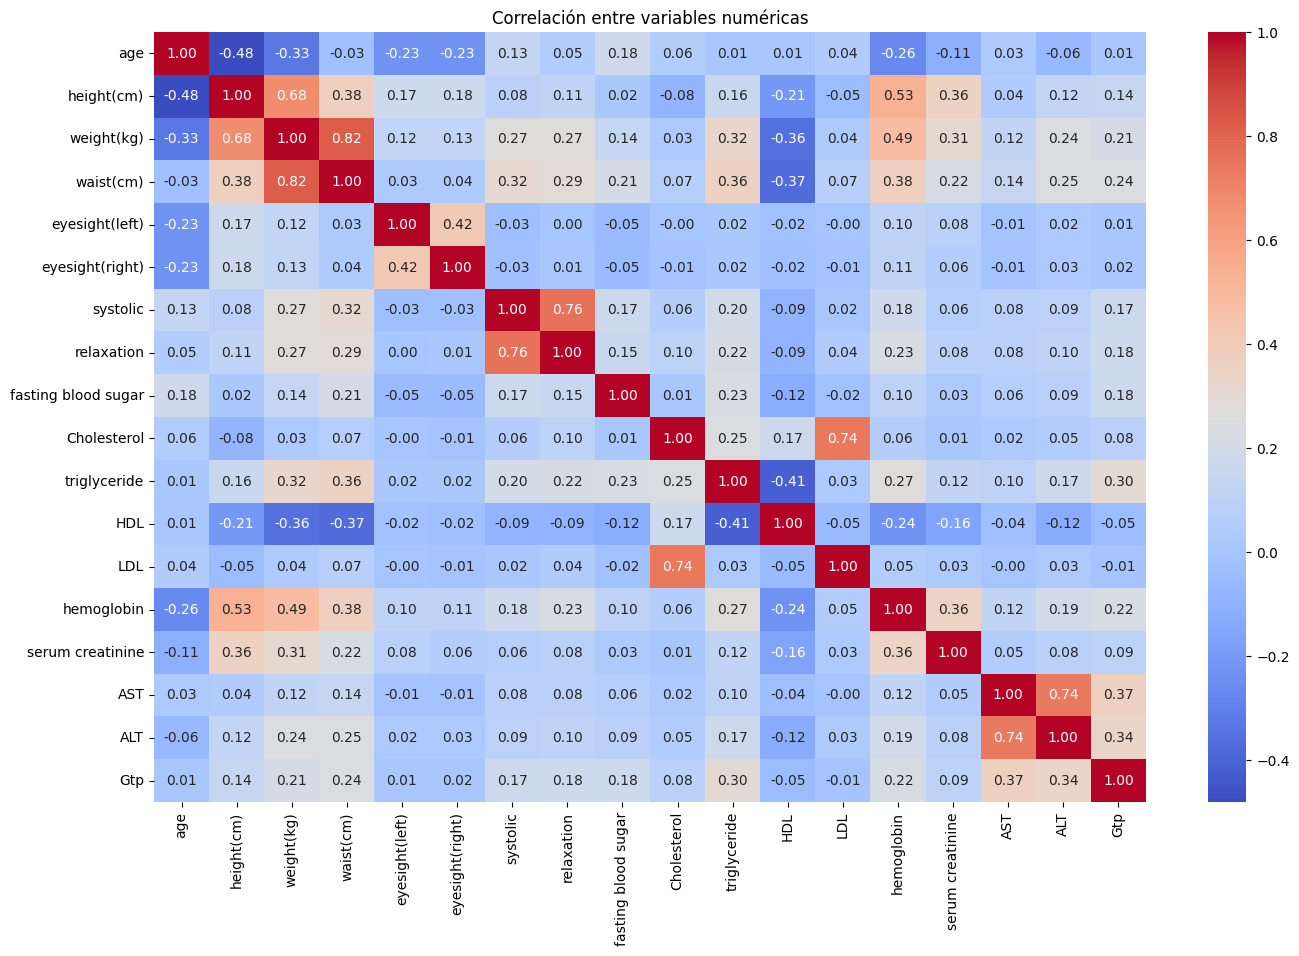

In [27]:
excluir = ["ID", "smoking", "dental caries","hearing(left)", "hearing(right)", "Urine protein"]
correlaciones = (df_etiq.drop(columns=excluir).select_dtypes(include="number").corr())
plt.figure(figsize=(16, 10))
sns.heatmap(correlaciones, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación entre variables numéricas")
plt.show()

**Correlaciones altas entre peso y cintura (0,82), presión sistólica y diastólica (0,76), colesterol y LDL (0,74), y AST y ALT (0,74).**
Cintura y peso tienen una corelacion bastante alta, evaluar durante el entrenamiento si conviene eliminar alguna

In [28]:
df_etiq.groupby(["gender", "smoking"])[VarClinicas].median().T

gender                      F                   M          
smoking                   0.0       1.0       0.0       1.0
systolic             4.916667  4.833333  5.083333  5.083333
relaxation           3.041667  3.041667  3.208333  3.250000
fasting blood sugar  3.916667  4.000000  4.000000  4.041667
Cholesterol          8.291667  8.125000  8.000000  8.083333
triglyceride         3.666667  4.250000  4.500000  5.541667
HDL                  2.583333  2.583333  2.208333  2.125000
LDL                  4.791667  4.500000  4.708333  4.625000
hemoglobin           0.543750  0.545139  0.627778  0.629167
serum creatinine     0.004861  0.004861  0.041667  0.041667
AST                  0.875000  0.875000  1.000000  1.000000
ALT                  0.666667  0.666667  1.000000  1.041667
Gtp                  0.708333  0.958333  1.166667  1.541667

In [29]:
for genero in ["F", "M"]:
    datos = df_etiq[df_etiq["gender"] == genero]
    medianas = datos.groupby("smoking")[VarClinicas].median().T
    medianas["Diferencia %"] = ((medianas[1.0] - medianas[0.0]) / medianas[0.0]) * 100
    print("Género:", genero)
    display(medianas.round(2))

Género: F


smoking,0.0,1.0,Diferencia %
systolic,4.92,4.83,-1.69
relaxation,3.04,3.04,0.00
fasting blood sugar,3.92,4.00,2.13
Cholesterol,8.29,8.12,-2.01
triglyceride,3.67,4.25,15.91
HDL,2.58,2.58,0.00
LDL,4.79,4.50,-6.09
hemoglobin,0.54,0.55,0.26
serum creatinine,0.00,0.00,0.00
AST,0.88,0.88,0.00


Género: M


smoking,0.0,1.0,Diferencia %
systolic,5.08,5.08,0.00
relaxation,3.21,3.25,1.30
fasting blood sugar,4.00,4.04,1.04
Cholesterol,8.00,8.08,1.04
triglyceride,4.50,5.54,23.15
HDL,2.21,2.12,-3.77
LDL,4.71,4.62,-1.77
hemoglobin,0.63,0.63,0.22
serum creatinine,0.04,0.04,0.00
AST,1.00,1.00,0.00


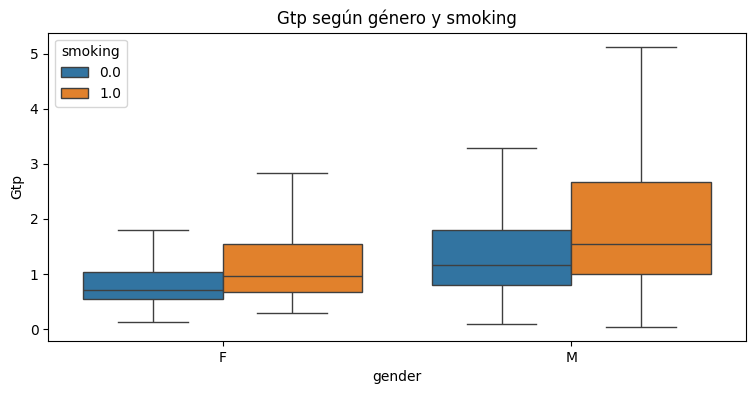

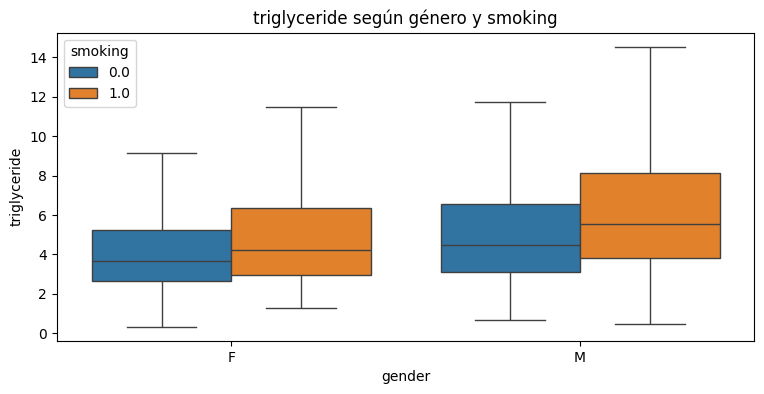

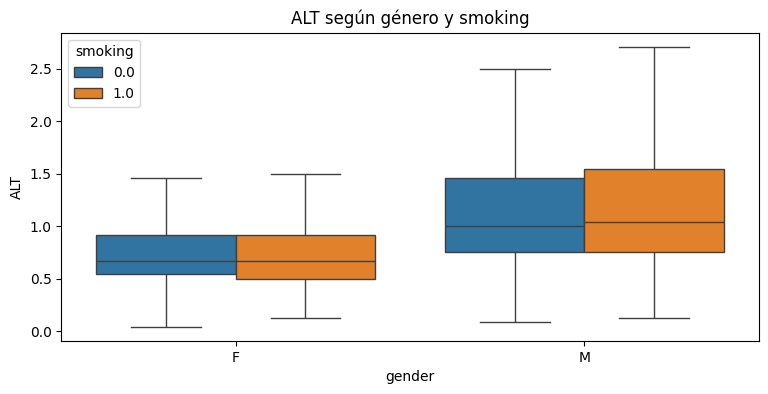

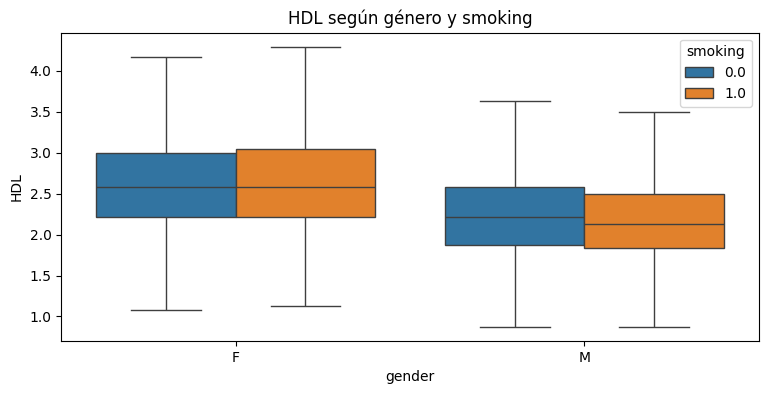

In [30]:
for variable in VarClinicasDestacadas:
    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=df_etiq,
        x="gender",
        y=variable,
        hue="smoking",
        showfliers=False
    )

    plt.title(f"{variable} según género y smoking")
    plt.show()

In [31]:
tabla_edad_genero = pd.crosstab(
    [df_etiq["gender"], df_etiq["age"]],
    df_etiq["smoking"],
    normalize="index") * 100

tabla_edad_genero.round(2)

smoking         0.0    1.0
gender age                
F      20.0   75.00  25.00
       25.0  100.00   0.00
       30.0   50.00  50.00
       40.0   94.30   5.70
       45.0   95.72   4.28
       50.0   96.07   3.93
       55.0   97.29   2.71
       60.0   96.45   3.55
       65.0   98.11   1.89
       70.0   98.44   1.56
       75.0   98.88   1.12
       80.0   98.97   1.03
       85.0  100.00   0.00
M      20.0   48.46  51.54
       25.0   53.42  46.58
       30.0   52.64  47.36
       35.0   46.99  53.01
       40.0   34.90  65.10
       45.0   35.60  64.40
       50.0   37.12  62.88
       55.0   43.19  56.81
       60.0   49.28  50.72
       65.0   61.66  38.34
       70.0   65.65  34.35
       75.0   76.66  23.34
       80.0   82.82  17.18
       85.0   91.67   8.33

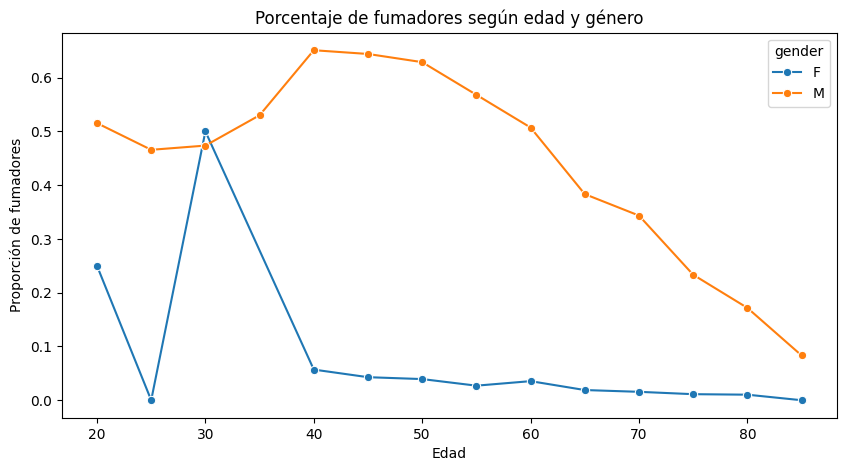

In [32]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=df_etiq,
    x="age",
    y="smoking",
    hue="gender",
    estimator="mean",
    errorbar=None,
    marker="o")
plt.title("Porcentaje de fumadores según edad y género")
plt.xlabel("Edad")
plt.ylabel("Proporción de fumadores")
plt.show()

In [33]:
pd.crosstab(df_etiq["age"],df_etiq["gender"])

gender,F,M
age,,
20.0,4,1426
25.0,6,3199
30.0,2,3621
35.0,0,4024
40.0,6475,7129
45.0,3221,3107
50.0,2415,2554
55.0,2290,2218
60.0,2678,2853


In [34]:
df_40_60 = df_etiq[
    df_etiq["age"].between(40, 60)]

df_40_60.groupby(
    ["gender", "smoking"]
)[["Gtp", "triglyceride"]].median()

Gtp  triglyceride
gender smoking                        
F      0.0      0.708333      3.625000
       1.0      0.958333      4.250000
M      0.0      1.291667      4.916667
       1.0      1.666667      5.916667

**Entre los 40 y 60 años, Gtp y triglyceride siguen siendo mayores en fumadores de ambos géneros**

In [35]:
df_40_60.groupby(
    ["gender", "age", "smoking"]
)[["Gtp", "triglyceride"]].median()

Gtp  triglyceride
gender age  smoking                        
F      40.0 0.0      0.625000      3.250000
            1.0      0.875000      4.041667
       45.0 0.0      0.666667      3.500000
            1.0      1.000000      4.000000
       50.0 0.0      0.750000      3.833333
            1.0      1.041667      4.666667
       55.0 0.0      0.833333      4.083333
            1.0      0.979167      4.625000
       60.0 0.0      0.833333      4.250000
            1.0      1.166667      5.000000
M      40.0 0.0      1.291667      4.958333
            1.0      1.708333      6.125000
       45.0 0.0      1.250000      5.166667
            1.0      1.750000      6.083333
       50.0 0.0      1.291667      4.916667
            1.0      1.666667      5.916667
       55.0 0.0      1.250000      4.791667
            1.0      1.645833      5.625000
       60.0 0.0      1.291667      4.666667
            1.0      1.625000      5.541667

In [36]:
df_40_60.groupby(
    ["gender", "age", "smoking"]
).size()

gender  age   smoking
F       40.0  0.0        6106
              1.0         369
        45.0  0.0        3083
              1.0         138
        50.0  0.0        2320
              1.0          95
        55.0  0.0        2228
              1.0          62
        60.0  0.0        2583
              1.0          95
M       40.0  0.0        2488
              1.0        4641
        45.0  0.0        1106
              1.0        2001
        50.0  0.0         948
              1.0        1606
        55.0  0.0         958
              1.0        1260
        60.0  0.0        1406
              1.0        1447
dtype: int64

**Al comparar por género y edad (40 a 60 años), Gtp y triglyceride siguen siendo mayores en fumadores en todos los grupo**

##SALUD DENTAL

In [37]:
pd.crosstab(
    [df_etiq["gender"], df_etiq["tartar"]],
    df_etiq["smoking"],
    normalize="index"
) * 100

smoking              0.0        1.0
gender tartar                      
F      N       96.755027   3.244973
       Y       94.769653   5.230347
M      N       50.523813  49.476187
       Y       40.567531  59.432469

In [38]:
pd.crosstab(
    [df_etiq["gender"], df_etiq["dental caries"]],
    df_etiq["smoking"],
    normalize="index") * 100

smoking                     0.0        1.0
gender dental caries                      
F      0.0            96.090969   3.909031
       1.0            93.893631   6.106369
M      0.0            47.025730  52.974270
       1.0            37.660972  62.339028

**Al separar por género, el porcentaje de fumadores sigue siendo mayor entre quienes tienen sarro o caries. La diferencia es más marcada en hombres**

In [39]:
df_etiq.nunique().sort_values().head(10)

,0
oral,1
gender,2
hearing(right),2
hearing(left),2
dental caries,2
tartar,2
smoking,2
Urine protein,6
height(cm),13
age,14


In [40]:
df_etiq["smoking"].value_counts(normalize=True) * 100

,proportion
smoking,
0.0,63.342
1.0,36.658


## Conclusiones del EDA

- **Distribución de fumadores:** el 36,66% fumadores Vs 63,34% no fumadores.
- **Género:** Diferencia entre hombres y mujeres. El 55,22% de los hombres fuma, frente al 4,28% de las mujeres.
- **Edad:** en los hombres, el porcentaje de fumadores es mayor entre los 40 y 50 años y disminuye a partir de los 55. En las mujeres también tiende a bajar, aunque hay muy pocos registros menores de 40 años.
- **Variables físicas:** inicialmente encontramos diferencias en altura y peso, pero al separar por género estas prácticamente desaparecen en las medianas.
- **Variables clínicas:** Gtp y triglyceride son las que más se destacan. Sus valores son mayores en fumadores, incluso al comparar por género y edad entre los 40 y 60 años.
- **Salud dental:** Mayor porcentaje de fumadores entre quienes presentan sarro o caries, tanto en hombres como en mujeres.
- **Correlaciones:** Variables presentan correlaciones altas: peso y cintura. Se decide conservarlas para evaluar su utilidad en los modelos.
- **Valores extremos:** Valores atípicos en algunas variables clínicas, pero no vamos a eliminarlos sin comprobar primero su impacto.
- **Variables a eliminar: oral** tiene un único valor, sumando a **ID** que  funciona como identificador de persona unica, por lo que no los vamamos a usar para entrenar.

Encontramos que **gender**, **age**, **Gtp**, **triglyceride**, **tartar** y **dental caries** podrían aportar información para predecir **smoking**.

**Se van a conservar el resto de las variables y evaluar su utilidad durante el entrenamiento**